[drive] Pasta base localizada via diretório 'polars': /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo
[aviso] argumentos não reconhecidos, ignorados: ['-f', '/root/.local/share/jupyter/runtime/kernel-366b26ee-d810-4579-9735-bd785ed678c2.json']
[diretório] Pasta de polares: /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/polars
[diretório] Pasta de saídas:  /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas

DIMENSIONAMENTO DO ROTOR
Diâmetro (D):            1.144 m
Altura (H):              2.974 m
Corda (c):               0.114 m
Área varrida (A):        3.401 m2
Raio (R):                0.572 m
Número de pás:           3
Razão de aspecto (H/D):  2.600
Solidez (sigma):         0.300
Potência nominal:        1000.0 W
Rotação em V nominal:    626.2 rpm
Torque em V nominal:     15.250 N.m
Re de corda em V nominal:3.040e+05
Referência de projeto:   D 1.144 m, H 2.974 m, c 0.114 m, A 3.401 

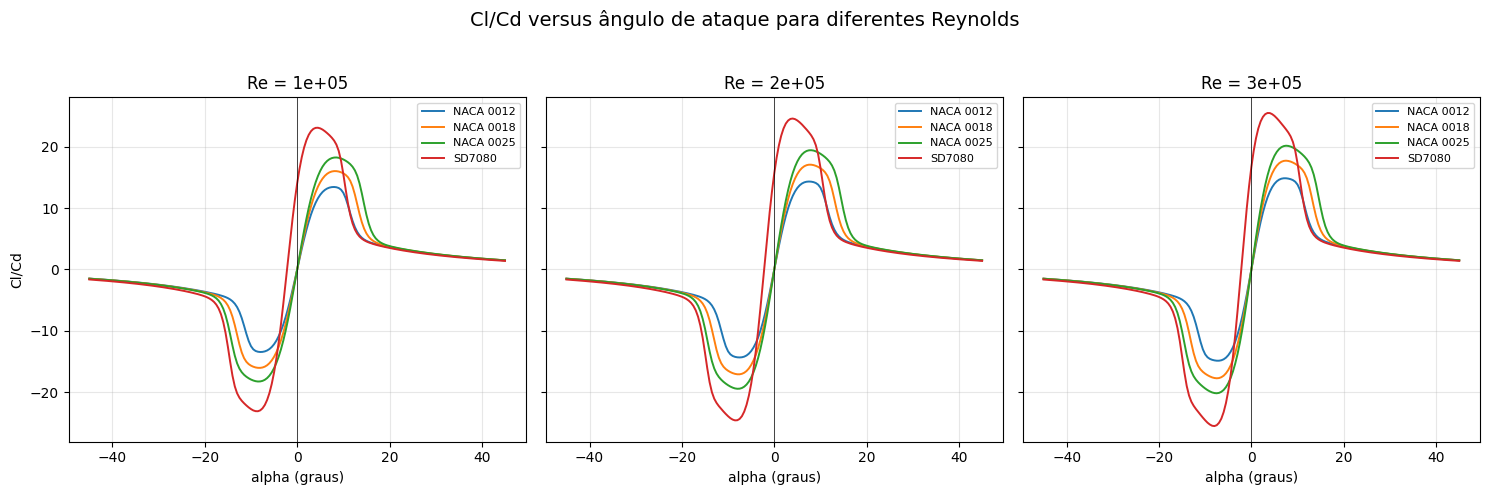

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig01_cl_cd_alpha.png


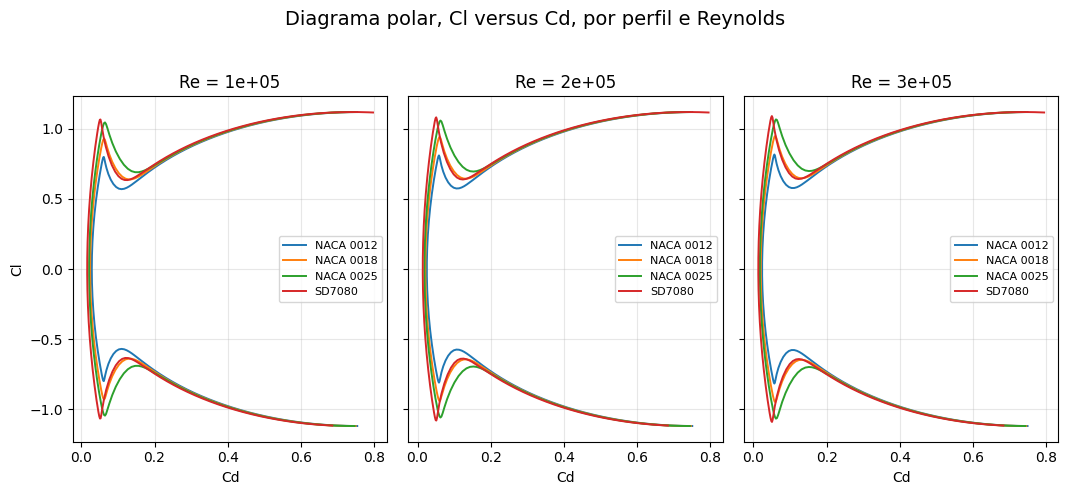

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig02_diagrama_polar.png


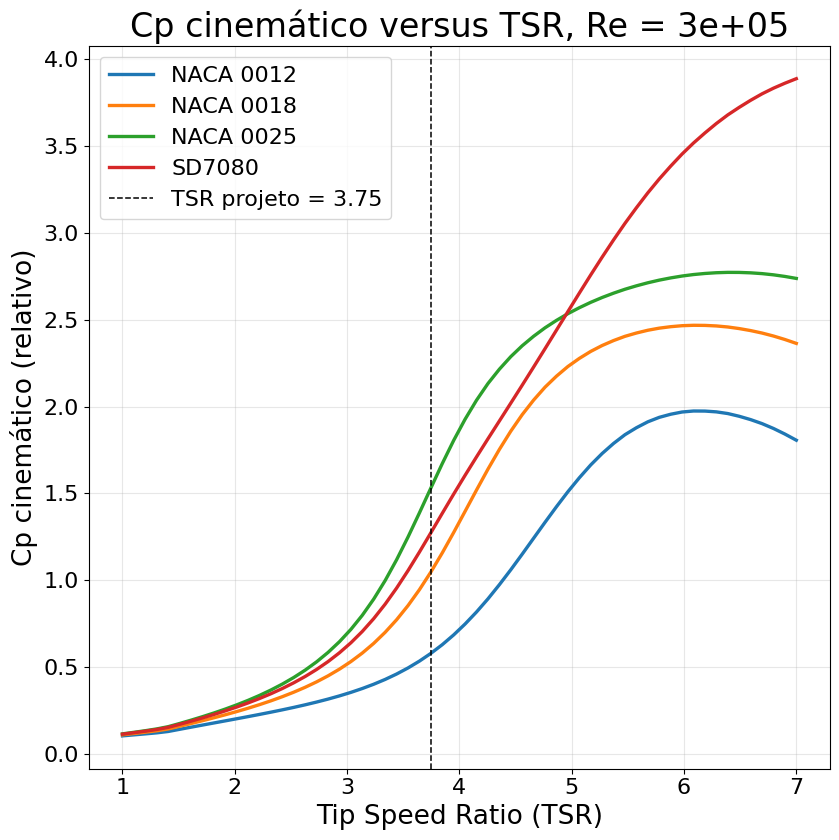

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig03_cp_tsr.png


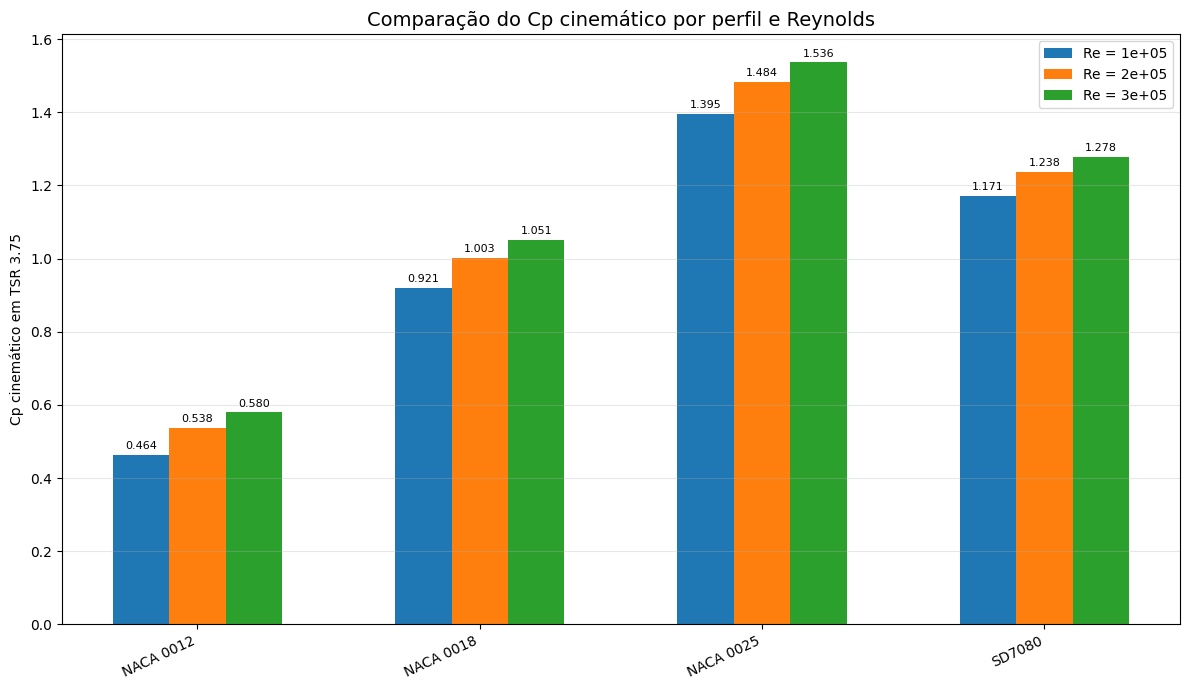

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig04_cp_barras.png


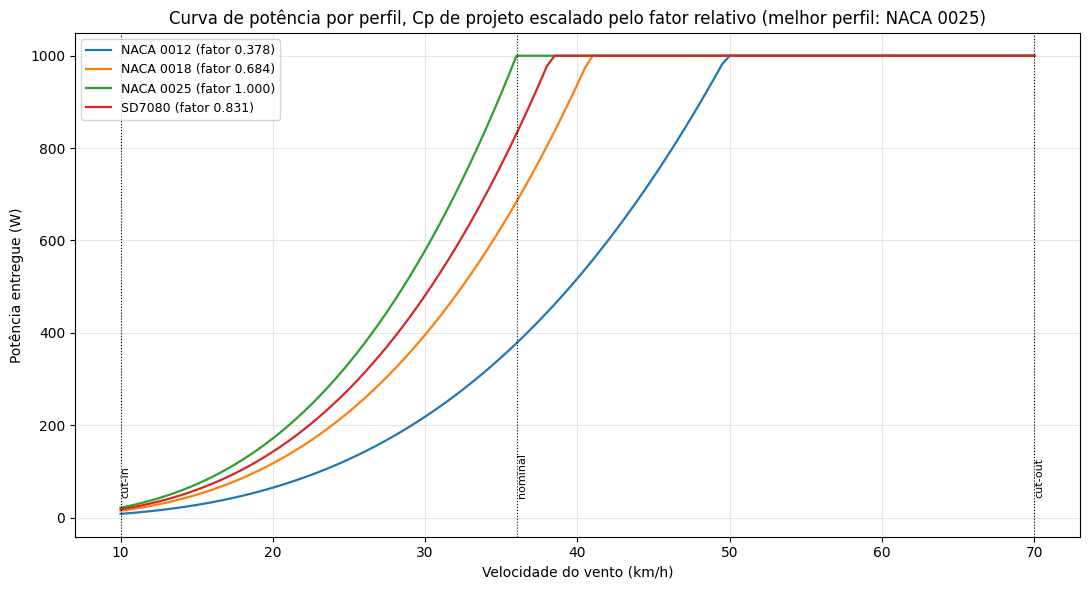

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig05_curva_potencia.png


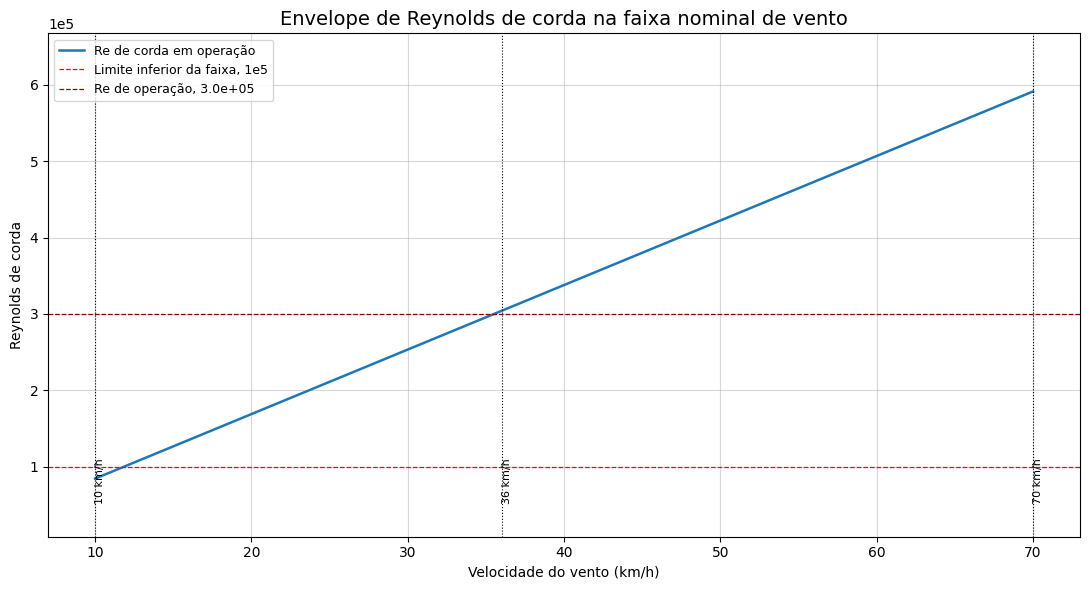

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig06_reynolds_operacao.png


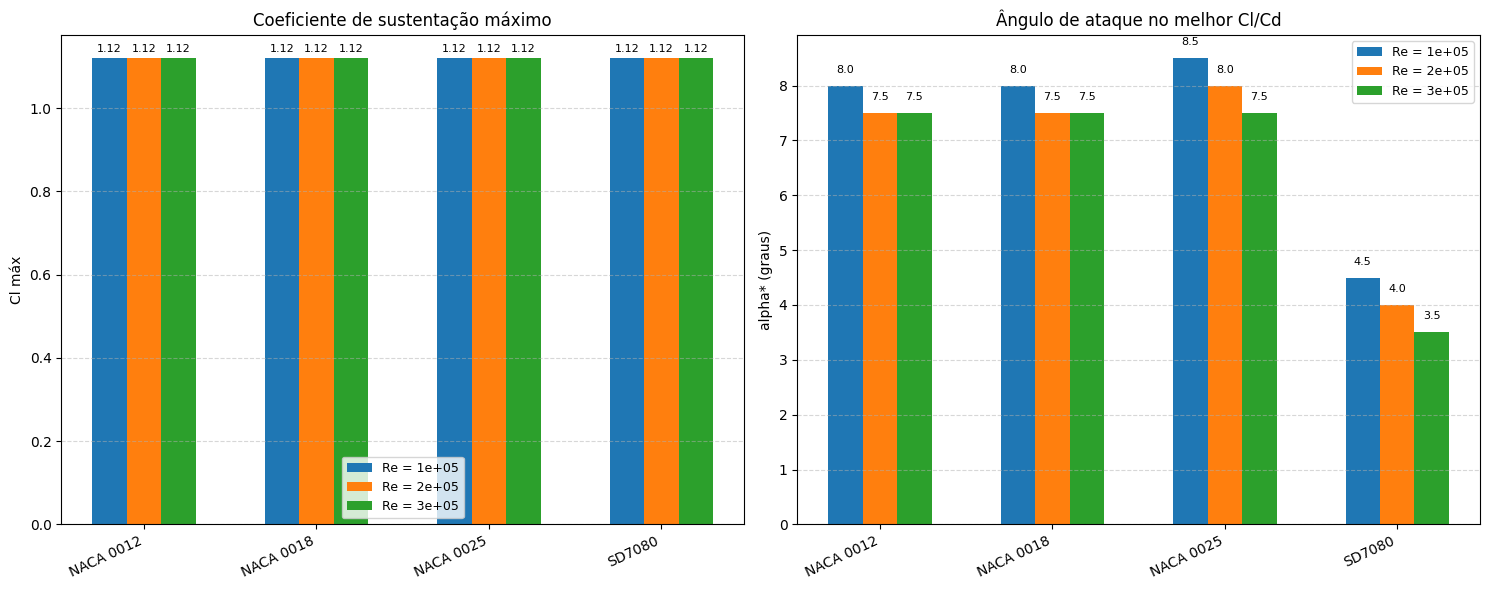

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig07_clmax_alpha.png


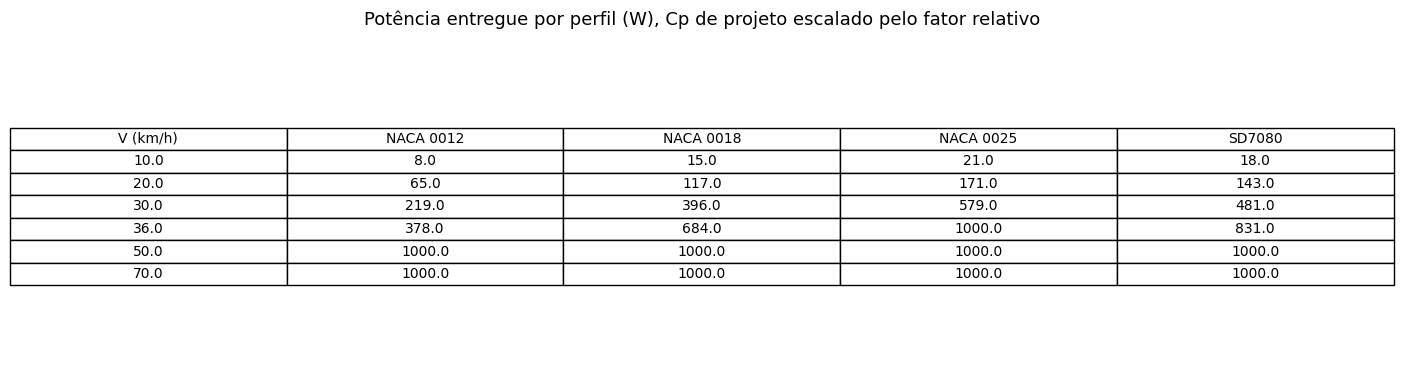

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig08_tabela_potencia.png


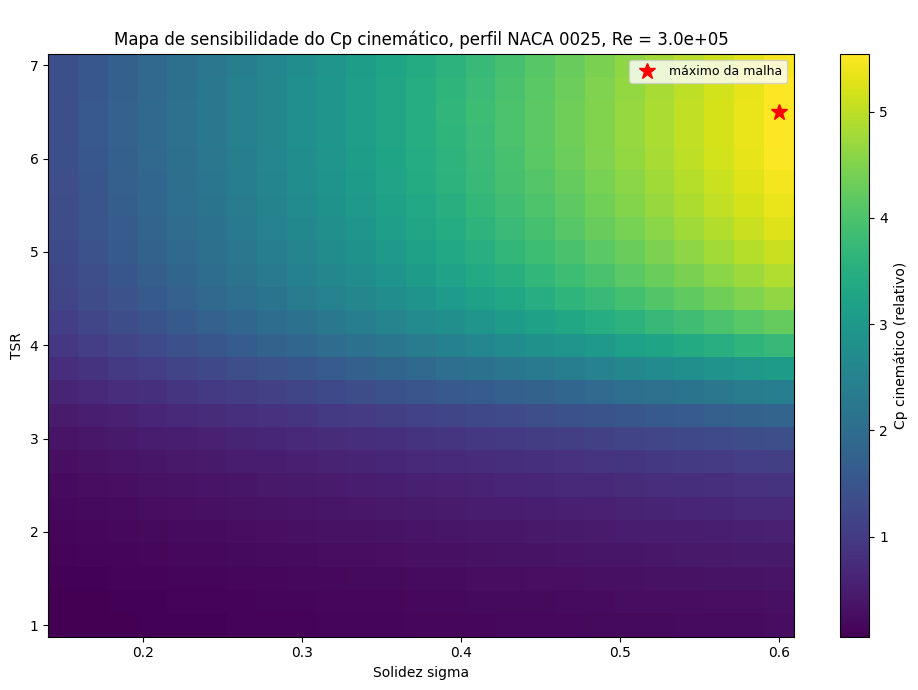

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig09_mapa_sensibilidade.png


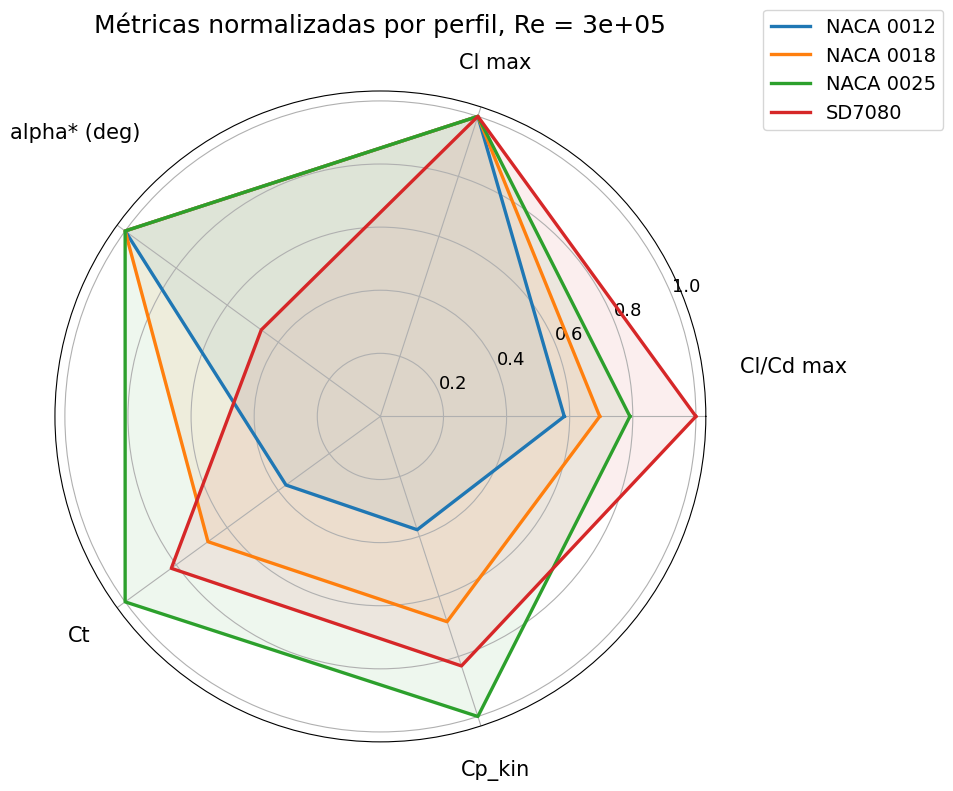

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig10_radar_metricas.png


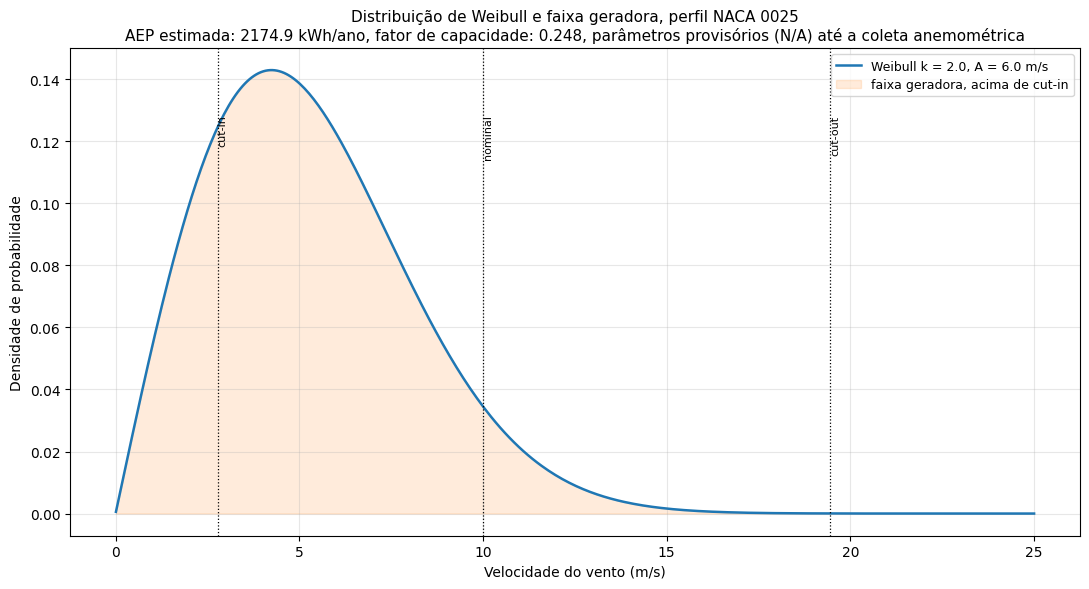

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig11_weibull_aep.png


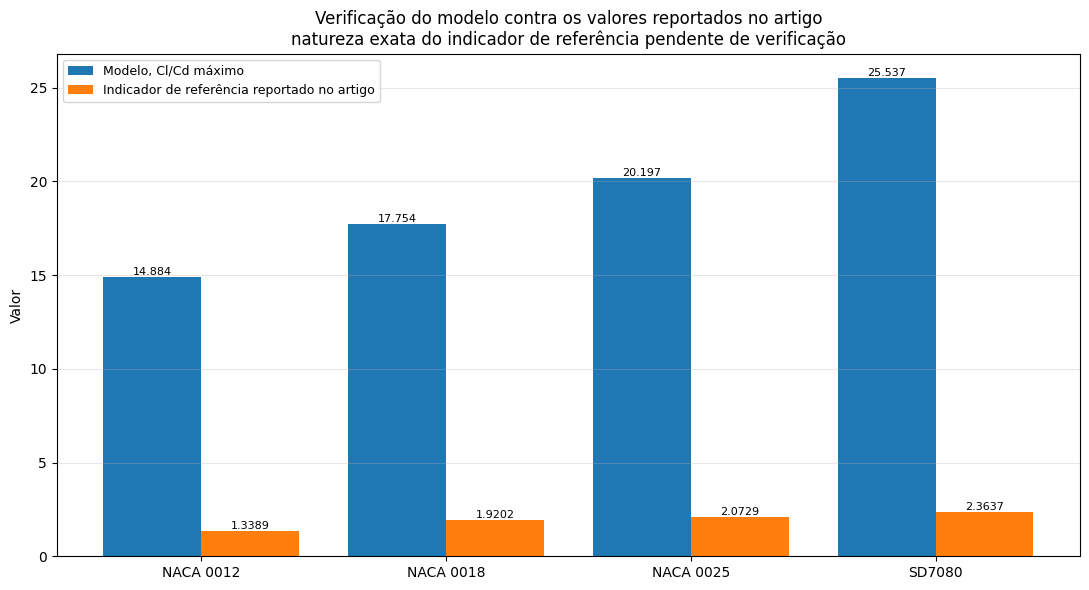

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig12_validacao_artigo.png


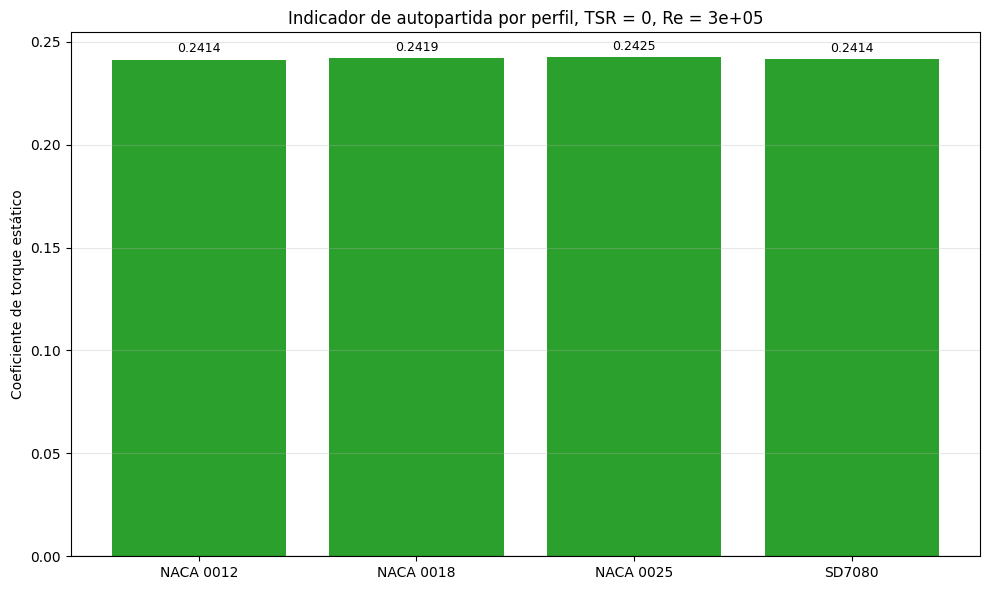

[figura] /content/drive/MyDrive/Projeto_EPE-Manufatura_WES_2026/Atividades/XV_CBPE/codigo/saidas/fig13_ct_estatico.png

Análise concluída com sucesso.


In [ ]:
"""
Programa XV_CBPE(rev07 - Google Drive Edition):
Modelagem matemática de rotor eólico de eixo vertical
do tipo H-Darrieus para microgeração.

Perfis contemplados no artigo de referência:
    NACA 0012, NACA 0018, NACA 0025 e SD7080

Ajuste de diretório:
    Montagem automática do Google Drive no Google Colab e resolução do
    diretório onde o programa/notebook está salvo, abrindo 'polars' e
    salvando 'saidas' diretamente na mesma pasta do programa.
"""

from __future__ import annotations

import argparse
import glob
import json
import math
import os
import urllib.error
import urllib.request
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================================================================
# 0. SELETOR DE ORIGEM: GITHUB OU GOOGLE DRIVE / COLAB
# =============================================================================

# Defina "github" para ler as polares do repositório morschfranco/AWT
# ou "drive" para abrir da mesma pasta do programa no Google Drive:
FONTE_EXECUCAO = "github"   # Opções: "github" ou "drive"

GITHUB_REPO_URL = "https://github.com/morschfranco/AWT/tree/main/XV_CBPE/Python"
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/morschfranco/AWT/main/XV_CBPE/Python"


def _baixar_polares_do_github(pasta_destino: str, perfis: list[str], re_list: list[float]):
    """Baixa os arquivos de polares diretamente do GitHub (morschfranco/AWT)
    para a pasta local caso ainda não estejam presentes."""
    os.makedirs(pasta_destino, exist_ok=True)
    baixados = 0
    for nome in perfis:
        base = nome.replace(" ", "").replace("-", "")
        for Re in re_list:
            # Verifica se já existe localmente com alguma extensão aceita
            if any(os.path.exists(os.path.join(pasta_destino, f"{base}_Re{int(Re)}{ext}"))
                   for ext in (".dat", ".csv", ".txt")):
                continue
            # Tenta buscar do GitHub nas extensões suportadas pelo programa
            for ext in (".dat", ".csv", ".txt"):
                nome_arq = f"{base}_Re{int(Re)}{ext}"
                url = f"{GITHUB_RAW_BASE}/polars/{nome_arq}"
                caminho_local = os.path.join(pasta_destino, nome_arq)
                try:
                    urllib.request.urlretrieve(url, caminho_local)
                    print(f"[github] Polar baixada: {nome_arq}")
                    baixados += 1
                    break
                except urllib.error.URLError:
                    continue
    if baixados == 0:
        print(f"[github] Verificação concluída em: {pasta_destino}")


def _localizar_pasta_no_drive() -> str:
    """Monta o Google Drive no Colab e retorna a pasta onde está o programa."""
    if "__file__" in globals():
        return os.path.dirname(os.path.abspath(__file__))

    try:
        from google.colab import drive, _message  # type: ignore
        if not os.path.ismount("/content/drive"):
            print("[drive] Montando Google Drive em /content/drive ...")
            drive.mount("/content/drive")
    except ImportError:
        return os.getcwd()

    cwd = os.getcwd()
    if cwd.startswith("/content/drive"):
        return cwd

    raizes = ["/content/drive/MyDrive", "/content/drive/Meu Drive"]
    raiz = next((r for r in raizes if os.path.exists(r)), "/content/drive/MyDrive")

    # 1. Tenta identificar a pasta exata do notebook aberto no Colab
    try:
        nb = _message.blocking_request("get_ipynb", timeout_sec=2)
        nome_nb = nb["ipynb"]["metadata"]["colab"]["name"]
        achados = glob.glob(os.path.join(raiz, "**", nome_nb), recursive=True)
        if achados:
            return os.path.dirname(achados[0])
    except Exception:
        pass

    # 2. Procura por 'XV_CBPE/Python' ou 'polars' dentro do Drive
    for padrao in (os.path.join(raiz, "**", "XV_CBPE", "Python"),
                   os.path.join(raiz, "**", "polars")):
        achados = glob.glob(padrao, recursive=True)
        if achados:
            return achados[0] if padrao.endswith("Python") else os.path.dirname(achados[0])

    pasta_colab = os.path.join(raiz, "Colab Notebooks")
    return pasta_colab if os.path.exists(pasta_colab) else raiz


def configurar_ambiente(fonte: str, perfis: list[str], re_list: list[float]) -> tuple[str, str]:
    """Define e retorna (PASTA_POLAR, PASTA_SAIDA) conforme a fonte escolhida."""
    fonte = fonte.lower().strip()

    if fonte == "github":
        # Se o repositório AWT foi clonado na sessão atual, usa a pasta clonada
        possiveis_clones = [
            os.path.abspath("XV_CBPE/Python"),
            os.path.abspath("AWT/XV_CBPE/Python"),
            "/content/AWT/XV_CBPE/Python",
        ]
        pasta_base = next((p for p in possiveis_clones if os.path.exists(p)), os.getcwd())
        pasta_polar = os.path.join(pasta_base, "polars")
        pasta_saida = os.path.join(pasta_base, "saidas")
        print(f"[ambiente] Modo GITHUB ativo ({GITHUB_REPO_URL})")
        _baixar_polares_do_github(pasta_polar, perfis, re_list)
        return pasta_polar, pasta_saida

    elif fonte == "drive":
        pasta_base = _localizar_pasta_no_drive()
        pasta_polar = os.path.join(pasta_base, "polars")
        pasta_saida = os.path.join(pasta_base, "saidas")
        print(f"[ambiente] Modo GOOGLE DRIVE ativo. Diretório base: {pasta_base}")
        return pasta_polar, pasta_saida

    else:
        raise ValueError("FONTE_EXECUCAO deve ser 'github' ou 'drive'.")


# =============================================================================
# 1. CONSTANTES E METADADOS
# =============================================================================

RHO_AIR = 1.225          # kg/m^3, ar ao nível do mar
NU_AIR = 1.46e-5         # m^2/s, viscosidade cinemática a cerca de 15 graus Celsius
CP_BETZ = 16.0 / 27.0

PERFIS_ARTIGO = ["NACA 0012", "NACA 0018", "NACA 0025", "SD7080"]
PERFIS_TODOS = PERFIS_ARTIGO

RE_LIST = [1.0e5, 2.0e5, 3.0e5]
RE_OPERACAO = 3.0e5

# Inicializa os caminhos de acordo com a variável FONTE_EXECUCAO ("github" ou "drive")
PASTA_POLAR, PASTA_SAIDA = configurar_ambiente(FONTE_EXECUCAO, PERFIS_TODOS, RE_LIST)

TSR_REF = 3.75           # TSR nominal de projeto
SIGMA_REF = 0.30         # solidez de projeto
N_PAS_REF = 3            # número de pás
AR_REF = 2.6             # razão altura/diâmetro (H/D)
CP_PROJ = 0.48           # Cp de projeto declarado

V_NOMINAL_MS = 10.0
P_NOMINAL_W = 1000.0
FAIXA_VENTO_KMH = (10.0, 70.0)   # faixa nominal de projeto declarada no artigo

V_CUT_IN_KMH = 10.0
V_CUT_OUT_KMH = 70.0

PERFIS_METADADOS = {
    "NACA 0012": {"familia": "NACA 4 dígitos, simétrico", "espessura_rel": 0.12},
    "NACA 0018": {"familia": "NACA 4 dígitos, simétrico", "espessura_rel": 0.18},
    "NACA 0025": {"familia": "NACA 4 dígitos, simétrico", "espessura_rel": 0.25},
    "SD7080": {"familia": "Série SD", "espessura_rel": None},
}

REFERENCIA_ARTIGO = {
    "indicador_re3e5": {"SD7080": 2.3637, "NACA 0025": 2.0729,
                        "NACA 0018": 1.9202, "NACA 0012": 1.3389},
    "indicador_re3e5_descricao": (
        "valores reportados no artigo para Re = 3 x 10^5. A natureza exata do "
        "indicador está pendente de confirmação no texto integral da fonte"
    ),
    "indicador_re3e5_desvios_pct": {"NACA 0025": 14.0, "NACA 0018": 23.0, "NACA 0012": 77.0},
    "cl_cd_max_naca0025": 22.1,
    "cl_max_reportado": {"valores": (1.43, 1.35), "atribuicao": None},
    "ranking_artigo": ["SD7080", "NACA 0025", "NACA 0018", "NACA 0012"],
    "reynolds_operacao": 3.0e5,
    "rotacao_operacao_rpm": 626.2,
    "dimensoes_artigo": {"D": 1.144, "H": 2.974, "c": 0.114, "A": 3.401, "R": 0.572},
}

# =============================================================================
# 2. POLARES
# =============================================================================


@dataclass
class Polar:
    nome: str
    Re: float
    alpha: list[float]
    cl: list[float]
    cd: list[float]
    origem: str          # rótulo de origem da polar, sempre "XFOIL"

    @staticmethod
    def _interp(x, xs, ys):
        """Interpolação linear com extrapolação constante nas bordas."""
        if x <= xs[0]:
            return ys[0]
        if x >= xs[-1]:
            return ys[-1]
        i = 0
        while i < len(xs) - 2 and x > xs[i + 1]:
            i += 1
        t = (x - xs[i]) / (xs[i + 1] - xs[i])
        return ys[i] + t * (ys[i + 1] - ys[i])

    def cl_cd(self, alpha_deg):
        return (self._interp(alpha_deg, self.alpha, self.cl),
                self._interp(alpha_deg, self.alpha, self.cd))

    def razao(self):
        return [cl / cd if cd > 0 else 0.0 for cl, cd in zip(self.cl, self.cd)]

    def resumo(self):
        razao = self.razao()
        i = razao.index(max(razao))
        return {
            "Cl/Cd max": max(razao),
            "alpha* (deg)": self.alpha[i],
            "Cl em alpha*": self.cl[i],
            "Cl max": max(self.cl),
            "Cd em alpha*": self.cd[i],
            "alpha de Cl max (deg)": self.alpha[self.cl.index(max(self.cl))],
        }

    def validar(self):
        """Diagnóstico de integridade da polar (salvaguarda de pré-avaliação)."""
        avisos = []
        if len(self.alpha) < 5:
            avisos.append("polar com menos de cinco pontos")
        if any(b <= a for a, b in zip(self.alpha, self.alpha[1:])):
            avisos.append("ângulos de ataque não estritamente crescentes")
        if any(c <= 0 for c in self.cd):
            avisos.append("coeficiente de arrasto não positivo em algum ponto")
        return avisos

    def para_dataframe(self):
        return pd.DataFrame({
            "Perfil": self.nome, "Re": self.Re, "alpha (deg)": self.alpha,
            "Cl": self.cl, "Cd": self.cd, "Cl/Cd": self.razao(),
            "Origem": self.origem,
        })


def _parse_polar(caminho: str, nome: str, Re: float) -> Polar:
    """Lê polar XFOIL (cabeçalhos ignorados) ou CSV simples com três colunas numéricas."""
    alphas, cls, cds = [], [], []
    with open(caminho, "r", encoding="utf-8", errors="replace") as fh:
        for linha in fh:
            partes = linha.replace(",", " ").split()
            if len(partes) < 3:
                continue
            try:
                a, cl, cd = float(partes[0]), float(partes[1]), float(partes[2])
            except ValueError:
                continue
            alphas.append(a)
            cls.append(cl)
            cds.append(cd)
    if len(alphas) < 3:
        raise ValueError(f"polar sem dados suficientes: {caminho}")
    return Polar(nome, Re, alphas, cls, cds, origem="XFOIL")


_CACHE_POLAR: dict[tuple[str, float, str], Polar | None] = {}


def _nome_arquivo_base(nome: str) -> str:
    return nome.replace(" ", "").replace("-", "")


def localizar_arquivo_polar(nome: str, Re: float, pasta: str = PASTA_POLAR) -> str | None:
    base = _nome_arquivo_base(nome)
    for ext in (".csv", ".txt", ".dat"):
        caminho = os.path.join(pasta, f"{base}_Re{int(Re)}{ext}")
        if os.path.exists(caminho):
            return caminho
    return None


def carregar_polar(nome: str, Re: float, pasta: str = PASTA_POLAR) -> Polar | None:
    """Devolve a polar do perfil e do Reynolds lida de arquivo externo (XFOIL),
    ou None quando o arquivo não existe. Nesse caso o perfil é excluído das
    comparações e figuras, com aviso no console."""
    chave = (nome, Re, pasta)
    if chave in _CACHE_POLAR:
        return _CACHE_POLAR[chave]
    caminho = localizar_arquivo_polar(nome, Re, pasta)
    polar = _parse_polar(caminho, nome, Re) if caminho is not None else None
    _CACHE_POLAR[chave] = polar
    return polar


def polar_disponivel(nome: str, re_list=RE_LIST, pasta: str = PASTA_POLAR) -> bool:
    return all(carregar_polar(nome, Re, pasta) is not None for Re in re_list)


def filtrar_perfis_disponiveis(perfis, re_list=RE_LIST, pasta: str = PASTA_POLAR):
    """Separa os perfis aptos à análise dos que ficam pendentes por falta de polar."""
    ok, pendentes = [], []
    for nome in perfis:
        (ok if polar_disponivel(nome, re_list, pasta) else pendentes).append(nome)
    return ok, pendentes


def diagnosticar_polares(perfis, re_list, pasta=PASTA_POLAR) -> pd.DataFrame:
    """Salvaguarda de pré-avaliação: verificações de sinal, faixa e suporte de entropia."""
    linhas = []
    for nome in perfis:
        for Re in re_list:
            pol = carregar_polar(nome, Re, pasta)
            if pol is None:
                linhas.append({
                    "Perfil": nome, "Re": Re, "Origem": "ausente", "N pontos": 0,
                    "alpha mín (deg)": None, "alpha máx (deg)": None,
                    "Cl máx": None, "Cd mín": None,
                    "Avisos": ("arquivo de polar não encontrado em "
                               f"{pasta}/{_nome_arquivo_base(nome)}_Re{int(Re)}.dat"),
                })
                continue
            avisos = pol.validar()
            linhas.append({
                "Perfil": nome, "Re": Re, "Origem": pol.origem,
                "N pontos": len(pol.alpha),
                "alpha mín (deg)": min(pol.alpha), "alpha máx (deg)": max(pol.alpha),
                "Cl máx": round(max(pol.cl), 4), "Cd mín": round(min(pol.cd), 5),
                "Avisos": "; ".join(avisos) if avisos else "sem avisos",
            })
    return pd.DataFrame(linhas)


# =============================================================================
# 3. DIMENSIONAMENTO
# =============================================================================


@dataclass
class Parametros:
    P_nominal: float = P_NOMINAL_W
    V_nominal: float = V_NOMINAL_MS
    Cp: float = CP_PROJ
    N_pas: int = N_PAS_REF
    AR: float = AR_REF
    sigma: float = SIGMA_REF
    TSR: float = TSR_REF
    rho: float = RHO_AIR
    nu: float = NU_AIR

    def __post_init__(self):
        if not (500.0 <= self.P_nominal <= 1000.0):
            raise ValueError("P_nominal deve estar entre 500 e 1000 W.")
        if self.Cp >= CP_BETZ:
            raise ValueError(f"Cp deve ser menor que o limite de Betz ({CP_BETZ:.3f}).")
        if self.AR <= 0 or self.sigma <= 0 or self.TSR <= 0:
            raise ValueError("AR, solidez e TSR devem ser positivos.")
        if not (2 <= self.N_pas <= 5):
            raise ValueError("N_pas deve estar entre 2 e 5, conforme a faixa recomendada.")


@dataclass
class Rotor:
    D: float
    H: float
    c: float
    A: float
    P_nominal: float
    V_nominal: float
    Cp: float
    TSR: float
    rho: float
    nu: float
    sigma: float
    AR: float
    N_pas: int

    @property
    def R(self) -> float:
        return self.D / 2.0

    def potencia(self, V: float, limitar: bool = True, cp: float | None = None) -> float:
        cp = cp if cp is not None else self.Cp
        P = 0.5 * self.rho * self.A * V**3 * cp
        return min(P, self.P_nominal) if limitar else P

    def rpm(self, V: float) -> float:
        return (self.TSR * V / self.R) * 60.0 / (2.0 * math.pi)

    def re_corda(self, V: float, tsr: float | None = None) -> float:
        tsr = tsr if tsr is not None else self.TSR
        W = V * math.sqrt(tsr * tsr + 1.0)
        return W * self.c / self.nu

    def torque(self, V: float, cp: float | None = None) -> float:
        cp = cp if cp is not None else self.Cp
        omega = self.TSR * V / self.R
        if omega <= 0:
            return 0.0
        return self.potencia(V, limitar=False, cp=cp) / omega


def dimensionar(p: Parametros) -> Rotor:
    A = p.P_nominal / (0.5 * p.rho * p.V_nominal**3 * p.Cp)   # A = D . H
    D = math.sqrt(A / p.AR)                                   # A = AR . D^2
    H = p.AR * D
    c = p.sigma * D / p.N_pas                                 # sigma = N . c / D
    r = Rotor(D=D, H=H, c=c, A=A, P_nominal=p.P_nominal, V_nominal=p.V_nominal,
              Cp=p.Cp, TSR=p.TSR, rho=p.rho, nu=p.nu, sigma=p.sigma,
              AR=p.AR, N_pas=p.N_pas)
    assert math.isclose(r.c * p.N_pas / r.D, p.sigma, rel_tol=1e-9)
    assert math.isclose(r.H / r.D, p.AR, rel_tol=1e-9)
    return r


# =============================================================================
# 4. MODELO CINEMÁTICO E MÉTRICAS POR PERFIL
# =============================================================================


def cp_cinematica(polar: Polar, tsr: float, sigma: float, n: int = 1440) -> float:
    """Cp relativo por perfil. Integração por soma de Riemann sobre [0, 2pi].
    Não usar como valor absoluto."""
    soma = 0.0
    for i in range(n):
        th = 2.0 * math.pi * i / n
        w2 = 1.0 + tsr * tsr + 2.0 * tsr * math.sin(th)
        alfa = math.degrees(math.atan2(math.cos(th), tsr + math.sin(th)))
        cl, cd = polar.cl_cd(alfa)
        ct = cl * math.sin(math.radians(alfa)) - cd * math.cos(math.radians(alfa))
        soma += w2 * ct
    return sigma * tsr * soma / n


def coef_torque(polar: Polar, tsr: float, sigma: float, n: int = 1440) -> float:
    """Coeficiente de torque médio, de modo que Cp = TSR . Ct. Em TSR = 0
    fornece o indicador de torque estático, relacionado à autopartida."""
    soma = 0.0
    for i in range(n):
        th = 2.0 * math.pi * i / n
        alfa = math.degrees(math.atan2(math.cos(th), tsr + math.sin(th)))
        cl, cd = polar.cl_cd(alfa)
        ct = cl * math.sin(math.radians(alfa)) - cd * math.cos(math.radians(alfa))
        soma += ct
    return sigma * soma / n


def curva_cp_tsr(polar: Polar, sigma: float, tsr_min=1.0, tsr_max=7.0, n=60):
    tsrs = np.linspace(tsr_min, tsr_max, n)
    cps = np.array([cp_cinematica(polar, float(t), sigma) for t in tsrs])
    return tsrs, cps


def comparar_perfis(perfis, re_list, tsr_ref=TSR_REF, sigma=SIGMA_REF, pasta=PASTA_POLAR):
    res = {}
    for nome in perfis:
        pol_disponivel = polar_disponivel(nome, re_list, pasta)
        res[nome] = {"_disponivel": pol_disponivel}
        if not pol_disponivel:
            continue
        for Re in re_list:
            pol = carregar_polar(nome, Re, pasta)
            info = pol.resumo()
            info["Cp_kin"] = cp_cinematica(pol, tsr_ref, sigma)
            info["Ct"] = coef_torque(pol, tsr_ref, sigma)
            info["Ct estatico"] = coef_torque(pol, 0.0, sigma)
            tsrs, cps = curva_cp_tsr(pol, sigma)
            info["tsr de Cp max"] = float(tsrs[int(np.argmax(cps))])
            info["fonte"] = pol.origem
            res[nome][Re] = info
    return res


def perfis_analisados(res):
    return [n for n, v in res.items() if v.get("_disponivel")]


def melhor_perfil(res, Re=RE_OPERACAO, chave="Cl/Cd max") -> str | None:
    candidatos = perfis_analisados(res)
    if not candidatos:
        return None
    return max(candidatos, key=lambda n: res[n][Re][chave])


def fatores_perfil(res, Re=RE_OPERACAO, chave="Cp_kin") -> tuple[dict, str | None]:
    """Fator relativo de potência por perfil, normalizado pelo melhor Cp_kin."""
    melhor = melhor_perfil(res, Re, chave)
    if melhor is None:
        return {}, None
    ref = res[melhor][Re][chave]
    if ref == 0:
        return {n: 0.0 for n in perfis_analisados(res)}, melhor
    return {n: res[n][Re][chave] / ref for n in perfis_analisados(res)}, melhor


def tabela_perfis(res, re_list) -> pd.DataFrame:
    linhas = []
    for nome in res:
        if not res[nome].get("_disponivel"):
            continue
        for Re in re_list:
            info = res[nome][Re]
            linhas.append({
                "Perfil": nome, "Re": Re,
                "Cl/Cd max": round(info["Cl/Cd max"], 4),
                "alpha* (deg)": round(info["alpha* (deg)"], 2),
                "Cl max": round(info["Cl max"], 4),
                "Ct": round(info["Ct"], 4),
                "Ct estatico": round(info["Ct estatico"], 4),
                "Cp_kin": round(info["Cp_kin"], 4),
                "TSR de Cp max": round(info["tsr de Cp max"], 2),
                "Origem": info["fonte"],
            })
    return pd.DataFrame(linhas)


# =============================================================================
# 5. VALIDAÇÃO CONTRA AS FONTES
# =============================================================================


def tabela_validacao(res, Re=RE_OPERACAO) -> pd.DataFrame:
    linhas = []
    for nome in PERFIS_ARTIGO:
        if not res.get(nome, {}).get("_disponivel"):
            continue
        info = res[nome][Re]
        ref = REFERENCIA_ARTIGO["indicador_re3e5"][nome]
        modelo = info["Cl/Cd max"]
        desvio = 100.0 * (modelo - ref) / ref if ref else float("nan")
        linhas.append({
            "Perfil": nome,
            "Cl/Cd max (modelo)": round(modelo, 4),
            "Indicador de referência (artigo)": ref,
            "Desvio relativo (%)": round(desvio, 2),
            "Origem da polar": info["fonte"],
            "Observação": "sem ressalvas",
        })
    return pd.DataFrame(linhas)


def verificar_ranking(res, Re=RE_OPERACAO):
    disponiveis = [n for n in PERFIS_ARTIGO if res.get(n, {}).get("_disponivel")]
    modelo = sorted(disponiveis, key=lambda n: res[n][Re]["Cl/Cd max"], reverse=True)
    referencia = [n for n in REFERENCIA_ARTIGO["ranking_artigo"] if n in disponiveis]
    return modelo, referencia, modelo == referencia


# =============================================================================
# 6. ENERGIA ANUAL E FATOR DE CAPACIDADE
# =============================================================================


def weibull_pdf(v, k, A):
    return (k / A) * (v / A) ** (k - 1) * np.exp(-(v / A) ** k)


def curva_potencia_perfil(rotor: Rotor, fator: float, v_kmh=None) -> pd.DataFrame:
    if v_kmh is None:
        v_kmh = np.linspace(FAIXA_VENTO_KMH[0], FAIXA_VENTO_KMH[1], 121)
    v_ms = np.asarray(v_kmh) / 3.6
    P = np.array([rotor.potencia(float(v), limitar=True, cp=CP_PROJ * fator) for v in v_ms])
    return pd.DataFrame({"V (km/h)": v_kmh, "V (m/s)": v_ms, "P (W)": P,
                         "RPM": [rotor.rpm(float(v)) for v in v_ms],
                         "Re corda": [rotor.re_corda(float(v)) for v in v_ms]})


def aep_weibull(rotor: Rotor, fator: float, k: float, A_weib: float,
                v_max=25.0, n=400, horas_ano=8760.0) -> dict:
    """Energia anual estimada por integração da curva de potência sobre a
    distribuição de Weibull. k e A são entradas do usuário; sem dado
    anemométrico do sítio, o resultado é provisório e reportado como N/A."""
    v = np.linspace(0.01, v_max, n)
    dv = v[1] - v[0]
    P = np.array([rotor.potencia(float(vi), limitar=True, cp=CP_PROJ * fator) for vi in v])
    p = weibull_pdf(v, k, A_weib)
    energia_kwh = float(np.sum(P * p) * dv * horas_ano / 1000.0)
    fc = energia_kwh / (rotor.P_nominal * horas_ano / 1000.0)
    return {"AEP (kWh/ano)": energia_kwh, "Fator de capacidade": fc,
            "Weibull k": k, "Weibull A (m/s)": A_weib,
            "Status dos parâmetros": "provisórios (N/A) até a coleta anemométrica"}


def varredura_sigma_tsr(polar: Polar, sigmas, tsrs) -> pd.DataFrame:
    dados = []
    for t in tsrs:
        for s in sigmas:
            dados.append({"sigma": float(s), "TSR": float(t),
                          "Cp_kin": cp_cinematica(polar, float(t), float(s))})
    return pd.DataFrame(dados)


def ranking_spearman(ordem_a, ordem_b) -> float:
    """Correlação de postos de Spearman sem dependência externa."""
    n = len(ordem_a)
    if n < 2:
        return float("nan")
    postos_a = {v: i for i, v in enumerate(ordem_a)}
    postos_b = {v: i for i, v in enumerate(ordem_b)}
    d2 = sum((postos_a[v] - postos_b[v]) ** 2 for v in ordem_a)
    return 1.0 - (6.0 * d2) / (n * (n * n - 1))


# =============================================================================
# 7. VISUALIZAÇÕES
# =============================================================================


def salvar_figura(fig, nome: str, args):
    caminho = os.path.join(args.outdir, f"{nome}.{args.formato}")
    fig.savefig(caminho, dpi=args.dpi, bbox_inches="tight")
    if args.mostrar:
        plt.show()
    else:
        plt.close(fig)
    print(f"[figura] {caminho}")


def _perfis_para_figura(perfis, re_list, pasta):
    ok, pendentes = filtrar_perfis_disponiveis(perfis, re_list, pasta)
    if pendentes:
        print(f"[aviso] perfis sem polar disponível, excluídos das figuras: "
              f"{', '.join(pendentes)}")
    return ok


def plotar_cl_cd_alpha(perfis, re_list, args):
    perfis = _perfis_para_figura(perfis, re_list, args.pasta_polar)
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 01 não gerada")
        return
    fig, axs = plt.subplots(1, len(re_list), figsize=(5 * len(re_list), 5), sharey=True)
    if len(re_list) == 1:
        axs = [axs]
    fig.suptitle("Cl/Cd versus ângulo de ataque para diferentes Reynolds", fontsize=14)
    for j, Re in enumerate(re_list):
        ax = axs[j]
        for nome in perfis:
            pol = carregar_polar(nome, Re, args.pasta_polar)
            ax.plot(pol.alpha, pol.razao(), lw=1.4, label=nome)
        ax.axvline(0, color="k", lw=0.5)
        ax.set_title(f"Re = {Re:.0e}")
        ax.set_xlabel("alpha (graus)")
        if j == 0:
            ax.set_ylabel("Cl/Cd")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    salvar_figura(fig, "fig01_cl_cd_alpha", args)


def plotar_polar_cl_cd(perfis, re_list, args):
    """fig02_diagrama_polar.png — escala horizontal reduzida (figura mais
    estreita), mantendo a altura original."""
    perfis = _perfis_para_figura(perfis, re_list, args.pasta_polar)
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 02 não gerada")
        return
    fig, axs = plt.subplots(1, len(re_list), figsize=(3.6 * len(re_list), 5), sharey=True)
    if len(re_list) == 1:
        axs = [axs]
    fig.suptitle("Diagrama polar, Cl versus Cd, por perfil e Reynolds", fontsize=14)
    for j, Re in enumerate(re_list):
        ax = axs[j]
        for nome in perfis:
            pol = carregar_polar(nome, Re, args.pasta_polar)
            ax.plot(pol.cd, pol.cl, lw=1.4, label=nome)
        ax.set_title(f"Re = {Re:.0e}")
        ax.set_xlabel("Cd")
        if j == 0:
            ax.set_ylabel("Cl")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    salvar_figura(fig, "fig02_diagrama_polar", args)


def plotar_cp_tsr(perfis, args, Re=RE_OPERACAO):
    """fig03_cp_tsr.png — fonte ampliada e largura reduzida, preservando os
    indicadores numéricos (eixos, título e legenda)."""
    perfis = _perfis_para_figura(perfis, [Re], args.pasta_polar)
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 03 não gerada")
        return
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    for nome in perfis:
        pol = carregar_polar(nome, Re, args.pasta_polar)
        tsrs, cps = curva_cp_tsr(pol, args.sigma)
        ax.plot(tsrs, cps, lw=2.4, label=nome)
    ax.axvline(args.tsr, ls="--", c="k", lw=1.1, label=f"TSR projeto = {args.tsr}")
    ax.set_title(f"Cp cinemático versus TSR, Re = {Re:.0e}", fontsize=24)
    ax.set_xlabel("Tip Speed Ratio (TSR)", fontsize=19)
    ax.set_ylabel("Cp cinemático (relativo)", fontsize=19)
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=16)
    fig.tight_layout()
    salvar_figura(fig, "fig03_cp_tsr", args)


def plotar_cp_barras(res, perfis, re_list, args):
    perfis = [n for n in perfis if res.get(n, {}).get("_disponivel")]
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 04 não gerada")
        return
    fig, ax = plt.subplots(figsize=(12, 7))
    x = np.arange(len(perfis))
    w = 0.2
    for j, Re in enumerate(re_list):
        vals = [res[n][Re]["Cp_kin"] for n in perfis]
        ax.bar(x + (j - 1) * w, vals, w, label=f"Re = {Re:.0e}")
        for i, val in enumerate(vals):
            ax.text(x[i] + (j - 1) * w, val + 0.01, f"{val:.3f}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(perfis, rotation=25, ha="right")
    ax.set_ylabel(f"Cp cinemático em TSR {args.tsr}")
    ax.set_title("Comparação do Cp cinemático por perfil e Reynolds", fontsize=14)
    ax.grid(alpha=0.3, axis="y")
    ax.legend(fontsize=10)
    fig.tight_layout()
    salvar_figura(fig, "fig04_cp_barras", args)


def plotar_curva_potencia(rotor, res, perfis, args):
    fatores, melhor = fatores_perfil(res)
    if melhor is None:
        print("[aviso] nenhuma polar disponível, figura 05 não gerada")
        return
    perfis = [n for n in perfis if n in fatores]
    fig, ax = plt.subplots(figsize=(11, 6))
    for nome in perfis:
        df = curva_potencia_perfil(rotor, fatores[nome])
        ax.plot(df["V (km/h)"], df["P (W)"], lw=1.6, label=f"{nome} (fator {fatores[nome]:.3f})")
    for v, rotulo in ((V_CUT_IN_KMH, "cut-in"), (36.0, "nominal"), (V_CUT_OUT_KMH, "cut-out")):
        ax.axvline(v, ls=":", c="k", lw=0.8)
        ax.text(v, ax.get_ylim()[1] * 0.04, rotulo, rotation=90, fontsize=8, va="bottom")
    ax.set_title(f"Curva de potência por perfil, Cp de projeto escalado pelo fator relativo "
                 f"(melhor perfil: {melhor})", fontsize=12)
    ax.set_xlabel("Velocidade do vento (km/h)")
    ax.set_ylabel("Potência entregue (W)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig05_curva_potencia", args)


def plotar_reynolds_operacao(rotor, args, Re=RE_OPERACAO):
    v_kmh = np.linspace(FAIXA_VENTO_KMH[0], FAIXA_VENTO_KMH[1], 121)
    re = np.array([rotor.re_corda(v / 3.6) for v in v_kmh])
    marcadores = [V_CUT_IN_KMH, 36.0, V_CUT_OUT_KMH]
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(v_kmh, re, lw=1.8, color="tab:blue", label="Re de corda em operação")
    for v in marcadores:
        ax.axvline(v, ls=":", c="k", lw=0.8)
        ax.text(v, min(re) * 0.6, f"{v:.0f} km/h", rotation=90, fontsize=8, va="bottom")
    ax.axhline(1.0e5, color="r", ls="--", lw=0.9, label="Limite inferior da faixa, 1e5")
    ax.axhline(Re, color="darkred", ls="--", lw=0.9, label=f"Re de operação, {Re:.1e}")
    ax.margins(y=0.15)
    ax.set_title("Envelope de Reynolds de corda na faixa nominal de vento", fontsize=14)
    ax.set_xlabel("Velocidade do vento (km/h)")
    ax.set_ylabel("Reynolds de corda")
    ax.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
    ax.grid(alpha=0.5)
    ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig06_reynolds_operacao", args)


def plotar_cl_max_alpha(res, perfis, re_list, args):
    perfis = [n for n in perfis if res.get(n, {}).get("_disponivel")]
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 07 não gerada")
        return
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    index = np.arange(len(perfis))
    bar_width = 0.2
    for i, Re in enumerate(re_list):
        cl_max = [res[n][Re]["Cl max"] for n in perfis]
        axs[0].bar(index + i * bar_width, cl_max, bar_width, label=f"Re = {Re:.0e}")
        for j, val in enumerate(cl_max):
            axs[0].text(index[j] + i * bar_width, val + 0.01, f"{val:.2f}",
                        ha="center", va="bottom", fontsize=8)
        a_estol = [res[n][Re]["alpha* (deg)"] for n in perfis]
        axs[1].bar(index + i * bar_width, a_estol, bar_width, label=f"Re = {Re:.0e}")
        for j, val in enumerate(a_estol):
            axs[1].text(index[j] + i * bar_width, val + 0.2, f"{val:.1f}",
                        ha="center", va="bottom", fontsize=8)
    for ax, titulo, rotulo in ((axs[0], "Coeficiente de sustentação máximo", "Cl máx"),
                               (axs[1], "Ângulo de ataque no melhor Cl/Cd", "alpha* (graus)")):
        ax.set_xticks(index + bar_width)
        ax.set_xticklabels(perfis, rotation=25, ha="right")
        ax.set_ylabel(rotulo)
        ax.set_title(titulo)
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig07_clmax_alpha", args)


def plotar_tabela_potencia(rotor, res, perfis, args):
    fatores, melhor = fatores_perfil(res)
    if melhor is None:
        print("[aviso] nenhuma polar disponível, figura 08 não gerada")
        return None
    perfis = [n for n in perfis if n in fatores]
    cp_best = res[melhor][RE_OPERACAO]["Cp_kin"]
    v_kmh = (10, 20, 30, 36, 50, 70)
    data = []
    for v in v_kmh:
        linha = [v]
        for nome in perfis:
            fator = res[nome][RE_OPERACAO]["Cp_kin"] / cp_best
            linha.append(round(rotor.potencia(v / 3.6, limitar=True, cp=CP_PROJ * fator), 0))
        data.append(linha)
    df = pd.DataFrame(data, columns=["V (km/h)"] + perfis)
    fig, ax = plt.subplots(figsize=(14, len(perfis) * 0.5 + 2))
    ax.axis("off")
    ax.set_title("Potência entregue por perfil (W), Cp de projeto escalado pelo fator relativo",
                 fontsize=13)
    tabela = ax.table(cellText=df.values, colLabels=df.columns, loc="center", cellLoc="center")
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(10)
    tabela.scale(1.2, 1.2)
    fig.tight_layout()
    salvar_figura(fig, "fig08_tabela_potencia", args)
    df.to_csv(os.path.join(args.outdir, "tabela_potencia.csv"), index=False)
    return df


def plotar_mapa_sensibilidade(res, args, perfil=None,
                              sigma_min=0.15, sigma_max=0.60, n_sigma=25,
                              tsr_min=1.0, tsr_max=7.0, n_tsr=25):
    """fig09_mapa_sensibilidade.png — título afastado do gráfico com uma
    linha em branco adicional."""
    perfil = perfil or melhor_perfil(res, chave="Cp_kin")
    if perfil is None:
        print("[aviso] nenhuma polar disponível, figura 09 não gerada")
        return None
    pol = carregar_polar(perfil, RE_OPERACAO, args.pasta_polar)
    df = varredura_sigma_tsr(pol, np.linspace(sigma_min, sigma_max, n_sigma),
                             np.linspace(tsr_min, tsr_max, n_tsr))
    Z = df.pivot_table(index="TSR", columns="sigma", values="Cp_kin", sort=False).values
    fig, ax = plt.subplots(figsize=(10, 7))
    mesh = ax.pcolormesh(np.linspace(sigma_min, sigma_max, n_sigma),
                         np.linspace(tsr_min, tsr_max, n_tsr), Z,
                         shading="auto", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Cp cinemático (relativo)")
    i_max = np.unravel_index(np.argmax(Z), Z.shape)
    ax.plot(np.linspace(sigma_min, sigma_max, n_sigma)[i_max[1]],
            np.linspace(tsr_min, tsr_max, n_tsr)[i_max[0]], "r*", ms=12,
            label="máximo da malha")
    ax.set_xlabel("Solidez sigma")
    ax.set_ylabel("TSR")
    ax.set_title(
        f"\nMapa de sensibilidade do Cp cinemático, perfil {perfil}, Re = {RE_OPERACAO:.1e}",
        fontsize=12
    )
    ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig09_mapa_sensibilidade", args)
    df.to_csv(os.path.join(args.outdir, "sensibilidade_sigma_tsr.csv"), index=False)
    return df


def plotar_radar(res, perfis, args, Re=RE_OPERACAO):
    """fig10_radar_metricas.png — fonte ampliada, rótulos de eixo deslocados
    manualmente ('Cl/Cd max' para cima/direita, 'alpha* (deg)' para
    cima/esquerda) e título distanciado do gráfico radar."""
    perfis = [n for n in perfis if res.get(n, {}).get("_disponivel")]
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 10 não gerada")
        return
    metricas = ["Cl/Cd max", "Cl max", "alpha* (deg)", "Ct", "Cp_kin"]
    valores = {n: [res[n][Re][m] for m in metricas] for n in perfis}
    maximos = [max(valores[n][i] for n in perfis) for i in range(len(metricas))]
    angulos = np.linspace(0, 2 * np.pi, len(metricas), endpoint=False).tolist()
    angulos_fechado = angulos + angulos[:1]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, polar=True)
    for nome in perfis:
        norm = [v / maximos[i] if maximos[i] else 0.0 for i, v in enumerate(valores[nome])]
        norm += norm[:1]
        ax.plot(angulos_fechado, norm, lw=2.4, label=nome)
        ax.fill(angulos_fechado, norm, alpha=0.08)

    ax.set_xticks(angulos)
    ax.set_xticklabels([])
    ax.tick_params(axis="y", labelsize=13)

    raio_rotulo = 1.18
    deslocamentos = {
        "Cl/Cd max": (0.14, 0.12),
        "alpha* (deg)": (0.14, -0.12),
    }
    for ang, nome_metrica in zip(angulos, metricas):
        dr, dtheta = deslocamentos.get(nome_metrica, (0.0, 0.0))
        ax.text(ang + dtheta, raio_rotulo + dr, nome_metrica,
                fontsize=15, ha="center", va="center")

    ax.set_title(f"Métricas normalizadas por perfil, Re = {Re:.0e}", fontsize=18, pad=42)
    ax.legend(loc="upper right", bbox_to_anchor=(1.38, 1.14), fontsize=14)
    fig.tight_layout()
    salvar_figura(fig, "fig10_radar_metricas", args)


def plotar_weibull(rotor, res, args, perfil=None):
    fatores, melhor = fatores_perfil(res)
    perfil = perfil or melhor
    if perfil is None:
        print("[aviso] nenhuma polar disponível, figura 11 não gerada")
        return None
    k, A = args.k_weibull, args.A_weibull
    v = np.linspace(0.01, 25.0, 400)
    pdf = weibull_pdf(v, k, A)
    P = np.array([rotor.potencia(float(vi), limitar=True, cp=CP_PROJ * fatores[perfil]) for vi in v])
    energia = aep_weibull(rotor, fatores[perfil], k, A)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(v, pdf, lw=1.8, color="tab:blue", label=f"Weibull k = {k}, A = {A} m/s")
    ax.fill_between(v, pdf, where=P > 0, color="tab:orange", alpha=0.15,
                    label="faixa geradora, acima de cut-in")
    for vv, rotulo in ((V_CUT_IN_KMH / 3.6, "cut-in"), (10.0, "nominal"),
                       (V_CUT_OUT_KMH / 3.6, "cut-out")):
        ax.axvline(vv, ls=":", c="k", lw=0.9)
        ax.text(vv, max(pdf) * 0.9, rotulo, rotation=90, fontsize=8, va="top")
    ax.set_title(f"Distribuição de Weibull e faixa geradora, perfil {perfil}\n"
                 f"AEP estimada: {energia['AEP (kWh/ano)']:.1f} kWh/ano, "
                 f"fator de capacidade: {energia['Fator de capacidade']:.3f}, "
                 f"parâmetros provisórios (N/A) até a coleta anemométrica", fontsize=11)
    ax.set_xlabel("Velocidade do vento (m/s)")
    ax.set_ylabel("Densidade de probabilidade")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig11_weibull_aep", args)
    return energia


def plotar_validacao(val_df: pd.DataFrame, args):
    if val_df.empty:
        print("[aviso] validação não aplicável, nenhuma polar do artigo disponível")
        return
    fig, ax = plt.subplots(figsize=(11, 6))
    x = np.arange(len(val_df))
    ax.bar(x - 0.2, val_df["Cl/Cd max (modelo)"], 0.4, label="Modelo, Cl/Cd máximo")
    ax.bar(x + 0.2, val_df["Indicador de referência (artigo)"], 0.4,
           label="Indicador de referência reportado no artigo")
    for i, (mod, ref) in enumerate(zip(val_df["Cl/Cd max (modelo)"],
                                       val_df["Indicador de referência (artigo)"])):
        ax.text(i - 0.2, mod, f"{mod:.3f}", ha="center", va="bottom", fontsize=8)
        ax.text(i + 0.2, ref, f"{ref:.4f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(val_df["Perfil"])
    ax.set_ylabel("Valor")
    ax.set_title("Verificação do modelo contra os valores reportados no artigo\n"
                 "natureza exata do indicador de referência pendente de verificação",
                 fontsize=12)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    salvar_figura(fig, "fig12_validacao_artigo", args)


def plotar_ct_estatico(res, perfis, args, Re=RE_OPERACAO):
    perfis = [n for n in perfis if res.get(n, {}).get("_disponivel")]
    if not perfis:
        print("[aviso] nenhuma polar disponível, figura 13 não gerada")
        return
    fig, ax = plt.subplots(figsize=(10, 6))
    vals = [res[n][Re]["Ct estatico"] for n in perfis]
    ax.bar(perfis, vals, color="tab:green")
    for i, v in enumerate(vals):
        ax.text(i, v + (0.002 if v >= 0 else -0.002), f"{v:.4f}",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_ylabel("Coeficiente de torque estático")
    ax.set_title(f"Indicador de autopartida por perfil, TSR = 0, Re = {Re:.0e}", fontsize=12)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    salvar_figura(fig, "fig13_ct_estatico", args)


# =============================================================================
# 8. RELATÓRIO E EXECUÇÃO PRINCIPAL
# =============================================================================


def imprimir_rotor(rotor: Rotor):
    print("=" * 68)
    print("DIMENSIONAMENTO DO ROTOR")
    print("=" * 68)
    print(f"Diâmetro (D):            {rotor.D:.3f} m")
    print(f"Altura (H):              {rotor.H:.3f} m")
    print(f"Corda (c):               {rotor.c:.3f} m")
    print(f"Área varrida (A):        {rotor.A:.3f} m2")
    print(f"Raio (R):                {rotor.R:.3f} m")
    print(f"Número de pás:           {rotor.N_pas}")
    print(f"Razão de aspecto (H/D):  {rotor.AR:.3f}")
    print(f"Solidez (sigma):         {rotor.sigma:.3f}")
    print(f"Potência nominal:        {rotor.P_nominal:.1f} W")
    print(f"Rotação em V nominal:    {rotor.rpm(rotor.V_nominal):.1f} rpm")
    print(f"Torque em V nominal:     {rotor.torque(rotor.V_nominal):.3f} N.m")
    print(f"Re de corda em V nominal:{rotor.re_corda(rotor.V_nominal):.3e}")
    print(f"Referência de projeto:   D {REFERENCIA_ARTIGO['dimensoes_artigo']['D']} m, "
          f"H {REFERENCIA_ARTIGO['dimensoes_artigo']['H']} m, "
          f"c {REFERENCIA_ARTIGO['dimensoes_artigo']['c']} m, "
          f"A {REFERENCIA_ARTIGO['dimensoes_artigo']['A']} m2, "
          f"rotação {REFERENCIA_ARTIGO['rotacao_operacao_rpm']} rpm")
    print()


def parse_args(argv=None):
    """Correção para o Google Colab: parse_known_args ignora os argumentos
    injetados pelo kernel do Jupyter, como '-f kernel-....json'."""
    ap = argparse.ArgumentParser(
        description="Análise paramétrica de rotor eólico de eixo vertical, perfis do artigo."
    )
    ap.add_argument("--pasta-polar", default=PASTA_POLAR)
    ap.add_argument("--outdir", default=PASTA_SAIDA)
    ap.add_argument("--formato", default="png", choices=["png", "pdf", "svg"])
    ap.add_argument("--dpi", type=int, default=200)
    ap.add_argument("--mostrar", dest="mostrar", action="store_true", default=True,
                    help="exibe os gráficos em janela (ativado por padrão)")
    ap.add_argument("--nao-mostrar", dest="mostrar", action="store_false",
                    help="desativa a exibição em janela, salva apenas os arquivos")
    ap.add_argument("--perfis", nargs="+", default=PERFIS_TODOS,
                    help="perfis a analisar, por exemplo NACA 0025 SD7080")
    ap.add_argument("--potencia", type=float, default=P_NOMINAL_W)
    ap.add_argument("--vento-nominal", type=float, default=V_NOMINAL_MS)
    ap.add_argument("--cp", type=float, default=CP_PROJ)
    ap.add_argument("--pas", type=int, default=N_PAS_REF)
    ap.add_argument("--ar", type=float, default=AR_REF)
    ap.add_argument("--sigma", type=float, default=SIGMA_REF)
    ap.add_argument("--tsr", type=float, default=TSR_REF)
    ap.add_argument("--k-weibull", type=float, default=2.0,
                    help="parâmetro de forma, provisório (N/A) até a coleta anemométrica")
    ap.add_argument("--A-weibull", type=float, default=6.0,
                    help="parâmetro de escala em m/s, provisório (N/A) até a coleta")
    ap.add_argument("--sem-graficos", action="store_true")
    args, desconhecidos = ap.parse_known_args(argv)
    if desconhecidos:
        print(f"[aviso] argumentos não reconhecidos, ignorados: {desconhecidos}")
    return args


def main(argv=None):
    args = parse_args(argv)
    os.makedirs(args.pasta_polar, exist_ok=True)
    os.makedirs(args.outdir, exist_ok=True)

    print(f"[diretório] Pasta de polares: {args.pasta_polar}")
    print(f"[diretório] Pasta de saídas:  {args.outdir}\n")

    p = Parametros(P_nominal=args.potencia, V_nominal=args.vento_nominal, Cp=args.cp,
                   N_pas=args.pas, AR=args.ar, sigma=args.sigma, TSR=args.tsr)
    rotor = dimensionar(p)
    imprimir_rotor(rotor)

    print("=" * 68)
    print("SALVAGUARDA DE PRÉ-AVALIAÇÃO DAS POLARES")
    print("=" * 68)
    diag = diagnosticar_polares(args.perfis, RE_LIST, args.pasta_polar)
    print(diag.to_string(index=False))
    diag.to_csv(os.path.join(args.outdir, "diagnostico_polares.csv"), index=False)
    print()

    res = comparar_perfis(args.perfis, RE_LIST, args.tsr, args.sigma, args.pasta_polar)
    disponiveis = perfis_analisados(res)
    pendentes = [n for n in args.perfis if n not in disponiveis]
    if pendentes:
        print("[aviso] perfis sem polar disponível, excluídos da análise: "
              f"{', '.join(pendentes)}")
        print("        esperado o arquivo "
              f"{args.pasta_polar}/<perfil>_Re<int(Re)>.dat para cada Re analisado")
        print()

    print("=" * 68)
    print(f"COMPARAÇÃO DE PERFIS, Cp cinemático em TSR {args.tsr}")
    print("=" * 68)
    for nome in disponiveis:
        print(f"\n{nome} ({PERFIS_METADADOS.get(nome, {}).get('familia', 'N/A')}):")
        for Re in RE_LIST:
            info = res[nome][Re]
            print(f"  Re = {Re:.0e}: Cp_kin = {info['Cp_kin']:.4f} | "
                  f"Ct = {info['Ct']:.4f} | Ct estático = {info['Ct estatico']:.4f} | "
                  f"Cl/Cd máx = {info['Cl/Cd max']:.2f} | Cl máx = {info['Cl max']:.2f} | "
                  f"origem = {info['fonte']}")
    df_perfis = tabela_perfis(res, RE_LIST)
    df_perfis.to_csv(os.path.join(args.outdir, "resultados_perfis.csv"), index=False)
    print()

    print("=" * 68)
    print("VALIDAÇÃO CONTRA O ARTIGO")
    print("=" * 68)
    df_val = tabela_validacao(res, RE_OPERACAO)
    if df_val.empty:
        print("sem dados, nenhuma polar dos perfis do artigo disponível")
    else:
        print(df_val.to_string(index=False))
        df_val.to_csv(os.path.join(args.outdir, "validacao_artigo.csv"), index=False)
        modelo, referencia, coincide = verificar_ranking(res, RE_OPERACAO)
        print(f"\nRanking do modelo:     {modelo}")
        print(f"Ranking de referência: {referencia}")
        print(f"Coincidência de ranking: {'sim' if coincide else 'não'}")
        print(f"Correlação de postos de Spearman: {ranking_spearman(modelo, referencia):.3f}")
    print()

    fatores, melhor = fatores_perfil(res)
    if melhor is None:
        print("[aviso] nenhum perfil com polar disponível, relatório de síntese não gerado")
        energia = {"AEP (kWh/ano)": None, "Fator de capacidade": None,
                   "Weibull k": args.k_weibull, "Weibull A (m/s)": args.A_weibull,
                   "Status dos parâmetros": "sem perfil analisável"}
    else:
        print(f"Melhor perfil pelo Cp cinemático: {melhor}")
        print("Fatores relativos de potência: " +
              ", ".join(f"{n} = {f:.3f}" for n, f in fatores.items()))
        energia = aep_weibull(rotor, fatores[melhor], args.k_weibull, args.A_weibull)
        print(f"AEP estimada ({melhor}): {energia['AEP (kWh/ano)']:.1f} kWh/ano | "
              f"fator de capacidade {energia['Fator de capacidade']:.3f} | "
              f"parâmetros de Weibull provisórios (N/A)")
    print()

    with open(os.path.join(args.outdir, "resumo.json"), "w", encoding="utf-8") as fh:
        json.dump({
            "parametros": vars(args),
            "rotor": {"D": rotor.D, "H": rotor.H, "c": rotor.c, "A": rotor.A,
                      "R": rotor.R, "rpm": rotor.rpm(rotor.V_nominal),
                      "torque_Nm": rotor.torque(rotor.V_nominal),
                      "Re_corda": rotor.re_corda(rotor.V_nominal)},
            "perfis_analisados": disponiveis,
            "perfis_pendentes": pendentes,
            "fatores_perfil": fatores,
            "melhor_perfil": melhor,
            "aep": energia,
            "referencia_artigo": REFERENCIA_ARTIGO,
        }, fh, ensure_ascii=False, indent=2)
    print(f"[dados] {os.path.join(args.outdir, 'resumo.json')}")

    if not args.sem_graficos:
        print("\nGerando visualizações.")
        plotar_cl_cd_alpha(args.perfis, RE_LIST, args)
        plotar_polar_cl_cd(args.perfis, RE_LIST, args)
        plotar_cp_tsr(args.perfis, args)
        plotar_cp_barras(res, args.perfis, RE_LIST, args)
        plotar_curva_potencia(rotor, res, args.perfis, args)
        plotar_reynolds_operacao(rotor, args)
        plotar_cl_max_alpha(res, args.perfis, RE_LIST, args)
        plotar_tabela_potencia(rotor, res, args.perfis, args)
        plotar_mapa_sensibilidade(res, args, perfil=melhor)
        plotar_radar(res, args.perfis, args)
        plotar_weibull(rotor, res, args, perfil=melhor)
        plotar_validacao(df_val, args)
        plotar_ct_estatico(res, args.perfis, args)

    print("\nAnálise concluída com sucesso.")
    return res, rotor


if __name__ == "__main__":
    main()